# Métricas de justiça: medindo o que discutimos em aula

no encontro 1, vimos que nenhuma escolha na construção de um algoritmo é neutra. hoje mudamos a pergunta:
**dado um algoritmo, como a gente mede se ele é justo?** 
e mais difícil: esse algoritmo é justo segundo **qual definição?**

usando o mesmo dataset da aula passada, vamos refazer o que fizemos à mão nos slides:

1. pegar o classificador de bolsas do encontro 1 e olhar pra ele grupo a grupo (escola pública vs particular);
2. calcular as métricas da aula: **paridade demográfica**, **igualdade de oportunidade**,
   **chances equalizadas**, **paridade preditiva** e **calibração**;
3. comparar três regras de seleção (as mesmas regras A, B e C dos slides) e ver que nenhuma satisfaz tudo;
4. voltar pro **ranking**: representação no top-k e **exposição**;
5. conhecer o **`fairlearn`**, uma biblioteca que calcula essas métricas e aplica técnicas de **mitigação**.

na aula, inventamos os números pra simplificar, mas aqui vamos usar os dados de verdade. pra surpresa de ninguém, eles são muito mais bagunçados. bora.

## 0. Aquisição de dados

### 0.1 Rodar local

1. Na página dos microdados do INEP: https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem
2. Baixe **ENEM 2023** (`microdados_enem_2023.zip`, aprox 600 MB).
3. O arquivo que precisamos é `DADOS/MICRODADOS_ENEM_2023.csv` (about 1.6 GB).

O arquivo `DICIONÁRIO/Dicionário_Microdados_Enem_2023.xlsx`) é um dicionário de dados e explica todos os códigos usados durante o nosso notebook. 

**Obs.**: Estamos pegando os dados de 2023 porque a partir de 2024, o INEP publicou as notas e as informações
dos participantes em arquivos diferentes sem colunas que nos permitam relacionar as coisas. Pra 
esse componente prático, precisamos de tudo numa mesma linha.)

In [9]:
# Mude pro caminho onde vc salvou seus dados
ARQUIVO_DADOS = "../encontro_1/microdados_enem_2023/DADOS/MICRODADOS_ENEM_2023.csv"

# O arquivo tem 3.9 milhões de linhas. 50.000 é suficiente pra gente ver o 
# impacto das decisões e mantém o notebook rápido.
TAMANHO_AMOSTRA = 50000

# Seed de gerador aleatório
RANDOM_SEED = 42

### 0.2 Rodar no Colab

Para rodar no Colab, vamos importar as bibliotecas necessárias e baixar um pacote adicional para para baixar os dados a partir de uma pasta compartilhada do Google Drive.

In [ ]:
!pip install --upgrade gdown

In [ ]:
!gdown https://drive.google.com/drive/folders/19MJuC6bg0pat6hIvN_hRKR0AZ71T_dNc?usp=sharing

In [ ]:
# Define o caminho para os dados
ARQUIVO_DADOS = "/content/ciencia_de_dados_responsável/MICRODADOS_ENEM_2023.csv"

# How many students we keep for the class (the full file has ~3.9 million rows).
# 50,000 is enough to see every effect and keeps the notebook fast.
TAMANHO_AMOSTRA = 50000

# Fixing the random seed makes everyone in the class get the same resultados
RANDOM_SEED = 42

## 1. importanto bibliotecas e dados

vamos usar exatamente os mesmos dados do encontro 1. colunas, filtros, amostra, seed etc. os números daqui batem com os de lá. (:  
se quiser rever por que cada filtro existe (e por que nenhum deles é neutro), volte no notebook do encontro 1.

In [2]:
%pip install -q fairlearn

Note: you may need to restart the kernel to use updated packages.


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score
from sklearn.model_selection import train_test_split

from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate
from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.reductions import ExponentiatedGradient, DemographicParity, EqualizedOdds

pd.set_option("display.precision", 1) # isso aqui é pra evitar um float com 123y12t3u163 casas depois da vírgula

In [11]:
colunas_selecionadas = [
    "TP_SEXO", "TP_COR_RACA", "TP_ESCOLA", "IN_TREINEIRO", "Q006", "Q002",
    "TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT",
    "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO",
]
colunas_notas = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]

dados_brutos = pd.read_csv(ARQUIVO_DADOS, sep=";", encoding="latin-1", usecols=colunas_selecionadas)

# Mesmos filtros do encontro 1
data = dados_brutos.copy()
for prova in ["CN", "CH", "LC", "MT"]:
    data = data[data[f"TP_PRESENCA_{prova}"] == 1]        # presentes em todas as provas
data = data[data["IN_TREINEIRO"] == 0]                    # não são treineiros
data = data[(data["TP_ESCOLA"] == 2) | (data["TP_ESCOLA"] == 3)]   # escola pública ou particular
data = data[data["TP_COR_RACA"].isin([1, 2, 3, 4, 5])]    # declararam raça/cor
data = data.dropna(subset=colunas_notas)

if len(data) > TAMANHO_AMOSTRA:
    data = data.sample(n=TAMANHO_AMOSTRA, random_state=RANDOM_SEED)
data = data.reset_index(drop=True)

# Mesmas colunas do encontro 1
data["escola_publica"] = (data["TP_ESCOLA"] == 2).astype(int)
data["ppi"] = data["TP_COR_RACA"].isin([2, 3, 5]).astype(int)
data["mulher"] = (data["TP_SEXO"] == "F").astype(int)

renda_numero = {letra: pos + 1 for pos, letra in enumerate("ABCDEFGHIJKLMNOPQ")}
data["renda_nivel"] = data["Q006"].map(renda_numero)
data["baixa_renda"] = (data["renda_nivel"] < data["renda_nivel"].median()).astype(int)

escolaridade_mae_numero = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "H": 4}
data["escolaridade_mae"] = data["Q002"].map(escolaridade_mae_numero)

data = data.dropna(subset=["renda_nivel", "escolaridade_mae"]).reset_index(drop=True)
data["media"] = data[colunas_notas].mean(axis=1)

print(f"Tamanho da amostra: {len(data)}")
print(f"Escola pública na amostra: {data['escola_publica'].mean():.1%}")

Tamanho da amostra: 50000
Escola pública na amostra: 79.2%


## 2. o classificador de bolsas do encontro 1

Relembrando: um programa de bolsas quer encontrar estudantes promissores antes da prova, usando só o
questionário socioeconômico. O modelo é o **Modelo A** do encontro 1 (tipo de escola, renda e escolaridade da mãe)
e o orçamento dá pra bolsas pra **25%** dos estudantes.

* **Rótulo** (`gt`): o estudante ficou entre os 25% com maior nota média no ENEM.
* **Predição** (`pred`): o modelo deu a bolsa pro estudante.
* **Grupo** (`G`): escola pública ou particular, como no exemplo da aula.

No encontro 1, olhamos duas colunas: *selecionados (%)* e *encontrados (%)*. Hoje elas ganham nome,
e a gente acrescenta as que faltavam.

In [37]:
corte_nota = data["media"].quantile(0.75)
data["gt"] = (data["media"] >= corte_nota).astype(int)

dados_treino, dados_teste = train_test_split(data, test_size=0.3, random_state=RANDOM_SEED)
dados_treino, dados_teste = dados_treino.copy(), dados_teste.copy()

features_A = ["escola_publica", "renda_nivel", "escolaridade_mae"]
modelo = LogisticRegression(max_iter=1000)
modelo.fit(dados_treino[features_A], dados_treino["gt"])
dados_teste["prob"] = modelo.predict_proba(dados_teste[features_A])[:, 1]

# mude esse número pra explorar outros cenários (mas só depois de ter rodado o notebook inteiro pela primeira vez)
PCT_BOLSA_DE_ESTUDOS = 0.25

def seleciona_pct_alta(probabilidades, pct):
    """Retorna 1 para os pct% com maior probabilidade e 0 pro resto (igual ao encontro 1)."""
    n_selecionados = int(len(probabilidades) * pct)
    ranks = pd.Series(probabilidades).rank(method="first", ascending=False)
    return (ranks <= n_selecionados).astype(int).values


dados_teste["pred_A"] = seleciona_pct_alta(dados_teste["prob"].values, PCT_BOLSA_DE_ESTUDOS)
print(f"estudantes no teste: {len(dados_teste)} | bolsas disponíveis: {dados_teste['pred_A'].sum()}")

estudantes no teste: 15000 | bolsas disponíveis: 3750


## 3. a matriz de confusão por grupo

mesma coisa dos slides, mas agora com o nosso cenário de classificação de bolsas de estudo:

* **verdadeiro positivo (TP)**: o modelo deu a bolsa pra quem de fato ficou entre as maiores notas;
* **falso positivo (FP)**: o modelo deu a bolsa pra quem não ficou entre as maiores notas;
* **falso negativo (FN)**: o estudante ficou entre as maiores notas e **não** recebeu a bolsa;
* **verdadeiro negativo (TN)**: não recebeu a bolsa e não ficou entre as maiores notas.

Todas as métricas da aula saem dessa tabela, por isso temos que dar uma olhada nela antes de tudo

In [13]:
NOMES_GRUPO = {0: "particular", 1: "pública"}

def matriz_por_grupo(df, pred, gt="gt", grupo="escola_publica"):
    """Conta TP, FP, FN e TN separadamente pra cada grupo."""
    tabela = {}
    for valor, nome in NOMES_GRUPO.items():
        g = df[df[grupo] == valor]
        tabela[nome] = {
            "candidatos": len(g),
            "com nota alta (gt = 1)": int((g[gt] == 1).sum()),
            "selecionados (pred = 1)": int((g[pred] == 1).sum()),
            "TP": int(((g[pred] == 1) & (g[gt] == 1)).sum()),
            "FP": int(((g[pred] == 1) & (g[gt] == 0)).sum()),
            "FN": int(((g[pred] == 0) & (g[gt] == 1)).sum()),
            "TN": int(((g[pred] == 0) & (g[gt] == 0)).sum()),
        }
    return pd.DataFrame(tabela)


matriz_por_grupo(dados_teste, "pred_A")

,particular,pública
candidatos,3120,11880
com nota alta (gt = 1),1849,1911
selecionados (pred = 1),3038,712
TP,1830,317
FP,1208,395
FN,19,1594
TN,63,9574


**Pra discutir:** compare com a tabela da *regra A* dos slides. que grupo tem mais falso negativo (FN)? em proporção ao tamanho
de cada grupo, a diferença continua a mesma? algo chama a atenção?

## 4. olhando as métricas

A função abaixo transforma a matriz de confusão nas taxas da aula. Cada métrica é só uma divisão diferente:

| métrica da aula | taxa | conta |
|---|---|---|
| paridade demográfica | taxa de seleção | (TP + FP) / candidatos |
| igualdade de oportunidade | TPR | TP / (TP + FN) |
| chances equalizadas | TPR **e** FPR | FP / (FP + TN) |
| paridade preditiva | PPV (precisão) | TP / (TP + FP) |

a **taxa base** é a fração do grupo com `gt = 1`, ou seja qual a porcentagem por grupo que vai tirar uma nota alta na prova (e, portanto, deveria ganhar uma bolsa). essa taxa não depende do modelo, e vai ser importante na seção 5.

In [14]:
def metricas_por_grupo(df, pred, gt="gt", grupo="escola_publica"):
    m = matriz_por_grupo(df, pred, gt, grupo).T
    return pd.DataFrame({
        "taxa base (%)": 100 * (m["TP"] + m["FN"]) / m["candidatos"],
        "seleção (%)": 100 * (m["TP"] + m["FP"]) / m["candidatos"],
        "TPR (%)": 100 * m["TP"] / (m["TP"] + m["FN"]),
        "FPR (%)": 100 * m["FP"] / (m["FP"] + m["TN"]),
        "PPV (%)": 100 * m["TP"] / (m["TP"] + m["FP"]),
    })


metricas_A = metricas_por_grupo(dados_teste, "pred_A")

In [15]:
metricas_A

,taxa base (%),seleção (%),TPR (%),FPR (%),PPV (%)
particular,59.3,97.4,99.0,95.0,60.2
pública,16.1,6.0,16.6,4.0,44.5


### 4.1 Paridade demográfica

**Pergunta:** os dois grupos são selecionados na mesma proporção?
$P(\text{pred} = 1 \mid G = g)$ igual pra todo $g$.

É a coluna *selecionados (%)* do encontro 1.

In [33]:
selecao = metricas_A["seleção (%)"]
print(selecao.round(1).to_string())
print(f"\nDiferença (particular − pública): {selecao['particular'] - selecao['pública']:.1f} pontos percentuais")
print(f"Razão (pública / particular):      {selecao['pública'] / selecao['particular']:.2f}")

particular    97.4
pública        6.0

Diferença (particular − pública): 91.4 pontos percentuais
Razão (pública / particular):      0.06


Uma regra muito usada na prática (a "regra dos 4/5", da legislação trabalhista dos EUA) considera preocupante
uma razão menor que 0,8.

**paridade em relação a quê?** a conta acima compara com os *candidatos* da amostra. mas mesmo quem chega a fazer o
ENEM já é um recorte. que outra referência faria sentido: os concluintes do ensino médio? a população do estado?

### 4.2 Igualdade de oportunidade

**Pergunta:** entre quem merece (`gt = 1`), todos têm a mesma chance de receber a bolsa?
$P(\text{pred} = 1 \mid \text{gt} = 1, G = g)$ igual pra todo $g$.

É a coluna *encontrados (%)* do encontro 1, também chamada de **TPR** ou **recall**.

In [17]:
metricas_A[["taxa base (%)", "TPR (%)"]]

,taxa base (%),TPR (%)
particular,59.3,99.0
pública,16.1,16.6


💬 Um estudante de escola pública que teria nota alta tem mais ou menos chance de receber a bolsa que um de escola
particular na mesma situação? O modelo nunca viu a nota de ninguém, só renda, escolaridade da mãe e tipo de escola.

### 4.3 Chances equalizadas

**Pergunta:** o modelo erra da mesma forma nos dois grupos? Agora são **duas** condições:

* **TPR igual**: quem merece tem a mesma chance de receber a bolsa;
* **FPR igual**: quem *não* teria nota alta tem a mesma chance de receber a bolsa "por engano".

É mais estrita que a igualdade de oportunidade, que olha só a TPR.

In [18]:
metricas_A[["TPR (%)", "FPR (%)"]]

,TPR (%),FPR (%)
particular,99.0,95.0
pública,16.6,4.0


💬 Numa bolsa de estudos, os dois erros pesam igual? Deixar de fora quem teria nota alta (FN) é tão grave quanto
dar a bolsa pra quem não teria (FP)?

### 4.4 Paridade preditiva

**Pergunta:** "receber a bolsa" significa a mesma coisa nos dois grupos? Entre os selecionados, a proporção com
nota alta deve ser igual. $P(\text{gt} = 1 \mid \text{pred} = 1, G = g)$ igual pra todo $g$.

In [19]:
metricas_A[["PPV (%)"]]

,PPV (%)
particular,60.2
pública,44.5


### 4.5 Calibração por grupo

Agora não olhamos a decisão (bolsa sim/não), e sim o **score** que o modelo dá (a probabilidade).
**Pergunta:** um mesmo score significa a mesma coisa nos dois grupos?

Lembra da previsão do tempo: se o app diz "70% de chance de chuva", deve chover em cerca de 70% desses dias,
em São Paulo ou em Fortaleza. Aqui: entre os estudantes com score ≈ 0,7, cerca de 70% deveriam ter nota alta,
nos dois grupos.

No gráfico, cada ponto agrupa estudantes com scores parecidos. Se o modelo é calibrado pra um grupo, os pontos
desse grupo ficam em cima da diagonal.

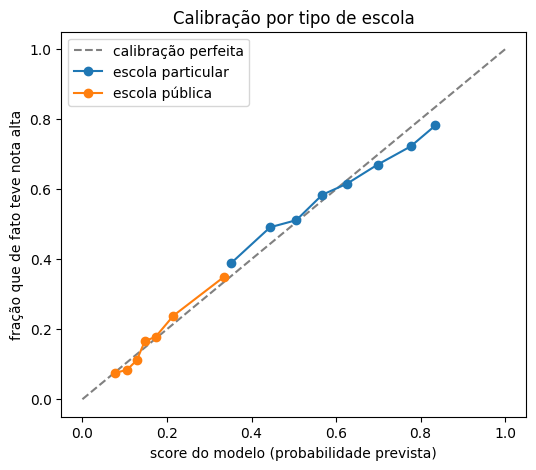

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="calibração perfeita")
for valor, nome in NOMES_GRUPO.items():
    g = dados_teste[dados_teste["escola_publica"] == valor]
    fracao_real, score_medio = calibration_curve(g["gt"], g["prob"], n_bins=8, strategy="quantile")
    ax.plot(score_medio, fracao_real, marker="o", label=f"escola {nome}")
ax.set_xlabel("score do modelo (probabilidade prevista)")
ax.set_ylabel("fração que de fato teve nota alta")
ax.set_title("Calibração por tipo de escola")
ax.legend()
plt.show()

💬 O modelo usa `escola_publica` como feature. Isso ajuda ou atrapalha a calibração por grupo? E se a gente tirasse
essa feature (como o Modelo C do encontro 1, só com renda)? Teste!

💬 Nos slides, a discussão era se uma mesma **nota do ENEM** significa a mesma coisa pra quem estudou em escola
pública e particular. Aqui, a pergunta é sobre o **score do modelo**. Qual das duas é mais fácil de verificar com dados?

### 4.6 usando o `fairlearn`

Até aqui calculamos tudo "na mão", a partir da matriz de confusão, pra ver de onde cada número vem. Na prática,
existem bibliotecas que fazem isso. A mais usada em Python é o [`fairlearn`](https://fairlearn.org).

O `MetricFrame` recebe o rótulo, a predição, o grupo e um dicionário de métricas, e calcula tudo por grupo.
Os números devem bater com os da seção 4.

In [21]:
def ppv(y_true, y_pred):
    return precision_score(y_true, y_pred, zero_division=0)


METRICAS = {
    "seleção": selection_rate,
    "TPR": true_positive_rate,
    "FPR": false_positive_rate,
    "PPV": ppv,
}

mf = MetricFrame(
    metrics=METRICAS,
    y_true=dados_teste["gt"],
    y_pred=dados_teste["pred_A"],
    sensitive_features=dados_teste["escola_publica"].map(NOMES_GRUPO),
)
display(mf.by_group * 100)
print("Diferença entre os grupos (em pontos percentuais):")
display(mf.difference() * 100)

,seleção,TPR,FPR,PPV
escola_publica,,,,
particular,97.4,99.0,95.0,60.2
pública,6.0,16.6,4.0,44.5


Diferença entre os grupos (em pontos percentuais):


seleção    91.4
TPR        82.4
FPR        91.1
PPV        15.7
dtype: float64

Além de `by_group` e `difference()`, o `MetricFrame` tem `ratio()` (a razão da regra dos 4/5) e aceita mais de um
grupo ao mesmo tempo em `sensitive_features`, o que ajuda na interseccionalidade (seção 6).

## 5. Três regras, como nos slides

Agora mantemos o **mesmo modelo e os mesmos scores** e mudamos só a regra que transforma o score em bolsa.
Todas as regras distribuem (aproximadamente) o mesmo número de bolsas: 25% dos estudantes.

* **Regra A — um corte pra todos:** os 25% com maior score. É o que fizemos até aqui.
* **Regra B — mesma TPR:** um corte diferente pra cada grupo, escolhido pra que quem merece tenha a mesma chance
  nos dois grupos (igualdade de oportunidade).
* **Regra C — mesma taxa de seleção:** os 25% com maior score *dentro de cada grupo* (paridade demográfica).
  É o "corte por tipo de escola" do encontro 1.

Nos slides, a regra B igualava TPR **e** FPR. Igualar as duas ao mesmo tempo é mais difícil, então aqui a regra B
iguala só a TPR. Logo abaixo, a **regra B'** usa o `fairlearn` pra igualar as duas.

In [22]:
def seleciona_mesma_tpr(df, prob, gt, grupo, pct):
    """Escolhe um corte por grupo de forma que a TPR seja (quase) igual nos grupos,
    aumentando a TPR-alvo até gastar o orçamento de bolsas."""
    n_bolsas = int(len(df) * pct)
    ordens = {}
    for valor in df[grupo].unique():
        g = df[df[grupo] == valor]
        ordem = g[prob].rank(method="first", ascending=False).sort_values().index
        tpr_acumulada = g.loc[ordem, gt].cumsum().values / g[gt].sum()
        ordens[valor] = (ordem, tpr_acumulada)

    for tpr_alvo in np.arange(0.001, 1.0, 0.001):
        n_por_grupo = {v: int(np.searchsorted(tpr, tpr_alvo)) + 1 for v, (_, tpr) in ordens.items()}
        if sum(n_por_grupo.values()) >= n_bolsas:
            break

    pred = pd.Series(0, index=df.index)
    for valor, (ordem, _) in ordens.items():
        pred.loc[ordem[: n_por_grupo[valor]]] = 1
    return pred.values


# Regra B
dados_teste["pred_B"] = seleciona_mesma_tpr(dados_teste, "prob", "gt", "escola_publica", PCT_BOLSA_DE_ESTUDOS)

# Regra C: 25% dentro de cada grupo
dados_teste["pred_C"] = 0
for valor in [0, 1]:
    linhas_grupo = dados_teste["escola_publica"] == valor
    dados_teste.loc[linhas_grupo, "pred_C"] = seleciona_pct_alta(
        dados_teste.loc[linhas_grupo, "prob"].values, PCT_BOLSA_DE_ESTUDOS)

REGRAS = {"A: um corte pra todos": "pred_A", "B: mesma TPR": "pred_B", "C: mesma seleção": "pred_C"}

### Regra B': TPR e FPR iguais, com o `fairlearn`

O `ThresholdOptimizer` pega um modelo já treinado e escolhe **um corte por grupo** que satisfaz uma restrição de
justiça, aqui as chances equalizadas (`"equalized_odds"`). Isso é **mitigação por pós-processamento**: o modelo não
muda, só a regra que transforma score em decisão. É o que fizemos à mão nas regras B e C.

Dois detalhes importantes:

* pra igualar TPR **e** FPR, ele **sorteia** parte das decisões perto do corte (por isso o `random_state`);
* ele não respeita o nosso orçamento de 25%: escolhe os cortes pra maximizar a acurácia balanceada.
  Repare no número de bolsas abaixo.

In [23]:
otimizador = ThresholdOptimizer(
    estimator=modelo,
    constraints="equalized_odds",
    objective="balanced_accuracy_score",
    prefit=True,
    predict_method="predict_proba",
)
otimizador.fit(dados_treino[features_A], dados_treino["gt"], sensitive_features=dados_treino["escola_publica"])
dados_teste["pred_B2"] = otimizador.predict(
    dados_teste[features_A], sensitive_features=dados_teste["escola_publica"], random_state=RANDOM_SEED)

REGRAS["B': TPR e FPR iguais (fairlearn)"] = "pred_B2"
for nome, coluna in REGRAS.items():
    print(f"{nome:36s} bolsas: {dados_teste[coluna].sum()}")

A: um corte pra todos                bolsas: 3750
B: mesma TPR                         bolsas: 3751
C: mesma seleção                     bolsas: 3750
B': TPR e FPR iguais (fairlearn)     bolsas: 5648


💬 Uma bolsa de estudos decidida, em parte, por sorteio é aceitável? E se a alternativa for uma regra que erra
sistematicamente mais com um grupo?

In [24]:
tabelas = {nome: metricas_por_grupo(dados_teste, coluna) for nome, coluna in REGRAS.items()}
comparacao = pd.concat(tabelas, names=["regra", "grupo"]).drop(columns="taxa base (%)")
comparacao

seleção (%)  TPR (%)  FPR (%)  \
regra                            grupo                                       
A: um corte pra todos            particular         97.4     99.0     95.0   
                                 pública             6.0     16.6      4.0   
B: mesma TPR                     particular         33.7     42.0     21.6   
                                 pública            22.7     42.0     19.0   
C: mesma seleção                 particular         25.0     31.7     15.3   
                                 pública            25.0     45.0     21.2   
B': TPR e FPR iguais (fairlearn) particular         45.4     54.7     31.7   
                                 pública            35.6     53.7     32.2   

                                             PPV (%)  
regra                            grupo                
A: um corte pra todos            particular     60.2  
                                 pública        44.5  
B: mesma TPR                     particular     73.9  
                                 pública        29.8  
C: mesma seleção                 particular     75.1  
                                 pública        28.9  
B': TPR e FPR iguais (fairlearn) particular     71.5  
                                 pública        24.2

### 5.1 Qual regra é justa?

Com dados reais, nenhuma diferença é exatamente zero. Vamos considerar que uma métrica está "satisfeita" quando a
diferença entre os grupos é de no máximo `TOLERANCIA` pontos percentuais. Mude o valor e veja o que acontece.

In [25]:
TOLERANCIA = 2  # pontos percentuais

criterios = {
    "paridade demográfica": ["seleção (%)"],
    "igualdade de oportunidade": ["TPR (%)"],
    "chances equalizadas": ["TPR (%)", "FPR (%)"],
    "paridade preditiva": ["PPV (%)"],
}

linhas = {}
for nome, tabela in tabelas.items():
    diferencas = (tabela.loc["particular"] - tabela.loc["pública"]).abs()
    linhas[nome] = {
        criterio: "✓" if all(diferencas[c] <= TOLERANCIA for c in colunas) else "✗"
        for criterio, colunas in criterios.items()
    }
pd.DataFrame(linhas).T

,paridade demográfica,igualdade de oportunidade,chances equalizadas,paridade preditiva
A: um corte pra todos,✗,✗,✗,✗
B: mesma TPR,✗,✓,✗,✗
C: mesma seleção,✓,✗,✗,✗
B': TPR e FPR iguais (fairlearn),✗,✓,✓,✗


### 5.2 Não é falta de esforço

Olhe de novo as **taxas base**: a fração de estudantes com nota alta em cada grupo.

In [26]:
metricas_A[["taxa base (%)"]]

,taxa base (%)
particular,59.3
pública,16.1


Quando as taxas base são diferentes, **não dá pra satisfazer tudo ao mesmo tempo** (Kleinberg et al., 2016;
Chouldechova, 2017), a não ser que o modelo seja perfeito. Igualar os erros faz "receber a bolsa" significar
coisas diferentes em cada grupo; fazer "receber a bolsa" significar o mesmo faz os erros ficarem diferentes.

Escolher uma métrica é escolher **quem arca com o erro**.

### 5.3 Quanto custa ser justo?

Uma objeção comum: "igualar os grupos piora a qualidade da seleção". Vamos medir. Pra cada regra: quantas bolsas
foram pra quem de fato teve nota alta (TP), a acurácia e quantas bolsas foram pra estudantes de escola pública.

In [27]:
custo = {}
for nome, coluna in REGRAS.items():
    selecionados = dados_teste[dados_teste[coluna] == 1]
    custo[nome] = {
        "bolsas": len(selecionados),
        "bolsas pra quem teve nota alta (TP)": int(selecionados["gt"].sum()),
        "acurácia (%)": 100 * (dados_teste[coluna] == dados_teste["gt"]).mean(),
        "bolsas pra escola pública": int(selecionados["escola_publica"].sum()),
    }
pd.DataFrame(custo).T.astype({"bolsas": int, "bolsas pra quem teve nota alta (TP)": int,
                               "bolsas pra escola pública": int})

,bolsas,bolsas pra quem teve nota alta (TP),acurácia (%),bolsas pra escola pública
A: um corte pra todos,3750,2147,78.6,712
B: mesma TPR,3751,1580,71.0,2699
C: mesma seleção,3750,1445,69.2,2970
B': TPR e FPR iguais (fairlearn),5648,2038,64.5,4233


**Para refletir:** A diferença em "qualidade" (TP, acurácia) é do mesmo tamanho que a diferença em **quem recebe a bolsa**?
Compare com o slide "quanto custa ser justo?".

## 6. Interseccionalidade

A regra C iguala escola pública e particular. Mas e dentro de cada tipo de escola? Vamos cruzar tipo de escola
com raça/cor (`ppi`) e olhar a taxa de seleção e a TPR em cada combinação.

In [28]:
dados_teste["escola × ppi"] = (
    dados_teste["escola_publica"].map(NOMES_GRUPO) + " / "
    + dados_teste["ppi"].map({0: "não PPI", 1: "PPI"})
)

inter = {}
for nome, coluna in REGRAS.items():
    g = dados_teste.groupby("escola × ppi")
    selecao = 100 * g[coluna].mean()
    tpr = 100 * dados_teste[dados_teste["gt"] == 1].groupby("escola × ppi")[coluna].mean()
    inter[(nome, "seleção (%)")] = selecao
    inter[(nome, "TPR (%)")] = tpr
pd.DataFrame(inter)

A: um corte pra todos         B: mesma TPR          \
                               seleção (%) TPR (%)  seleção (%) TPR (%)   
escola × ppi                                                              
particular / PPI                      95.0    98.0         20.5    28.2   
particular / não PPI                  98.3    99.3         38.9    46.4   
pública / PPI                          3.7    11.2         16.8    33.4   
pública / não PPI                      9.3    21.0         31.4    49.1   

                     C: mesma seleção          \
                          seleção (%) TPR (%)   
escola × ppi                                    
particular / PPI                 12.7    18.1   
particular / não PPI             29.8    36.0   
pública / PPI                    18.6    36.0   
pública / não PPI                34.4    52.3   

                     B': TPR e FPR iguais (fairlearn)          
                                          seleção (%) TPR (%)  
escola × ppi                                                   
particular / PPI                                 30.8    41.5  
particular / não PPI                             51.0    58.9  
pública / PPI                                    28.9    44.0  
pública / não PPI                                45.4    61.6

💬 Uma regra pode ser justa pra "escola pública" e pra "PPI" separadamente e, ainda assim, deixar pra trás quem está
nos dois grupos ao mesmo tempo? O que acontece se você trocar o grupo da regra C de `escola_publica` pra `ppi`?

## 7. Voltando ao rótulo

Todas as métricas acima comparam a predição com o rótulo `gt`. Mas o que é o nosso rótulo? "Ficar entre os 25% com
maior nota no ENEM". No encontro 1 vimos que trocar a definição (média, matemática, redação) muda quem é
"bom aluno" (Controle 3).

Hoje, a pergunta é outra: **as diferenças nas taxas base são um fato sobre os estudantes ou sobre as condições que
eles tiveram?**

In [29]:
taxa_base = data.groupby(["escola_publica", "baixa_renda"])["gt"].mean().mul(100).unstack()
taxa_base.index = taxa_base.index.map(NOMES_GRUPO).rename("escola")
taxa_base.columns = ["renda acima da mediana", "renda abaixo da mediana"]
taxa_base.round(1)

,renda acima da mediana,renda abaixo da mediana
escola,,
particular,60.6,36.4
pública,21.6,8.5


💬 Pra discutir:

* Uma regra que acerta muito bem esse rótulo está aprendendo o "mérito" dos estudantes ou as desigualdades que
  já estão na nota?
* Nos slides, o rótulo era "ter IRA alto no curso". Esse dado não está no ENEM. O que mudaria se a gente tivesse?
  E esse rótulo seria mais "neutro"?
* Se as taxas base fossem iguais, o problema da seção 5.2 desapareceria?

## 8. Ranking: a posição importa

### 8.1 O vestibular é um top-k

No encontro 1, olhamos quem entra num único corte (os 5% melhores). Mas em ranking a pergunta é sobre **cada pedaço
do topo**: top-1%, top-5%, top-20%… Abaixo, ordenamos todos os estudantes pela nota média e olhamos a porcentagem
de escola pública em cada top-k.

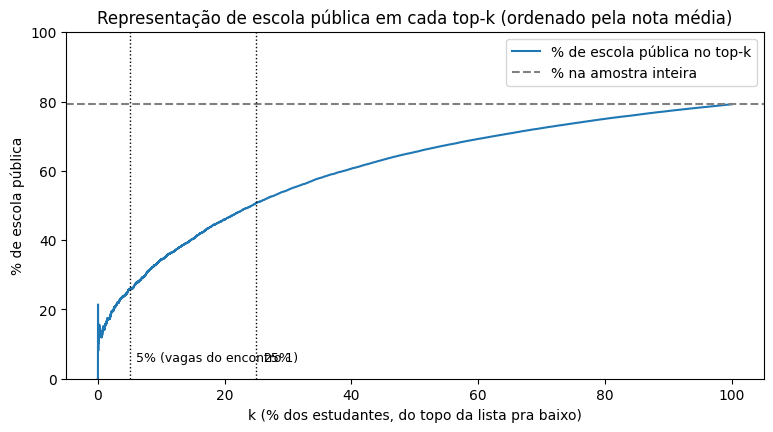

In [30]:
ordenados = data.sort_values("media", ascending=False).reset_index(drop=True)
k = np.arange(1, len(ordenados) + 1)
pct_publica_topk = 100 * ordenados["escola_publica"].cumsum() / k
pct_k = 100 * k / len(ordenados)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pct_k, pct_publica_topk, label="% de escola pública no top-k")
ax.axhline(100 * data["escola_publica"].mean(), linestyle="--", color="gray", label="% na amostra inteira")
for corte, texto in [(5, "5% (vagas do encontro 1)"), (25, "25%")]:
    ax.axvline(corte, linestyle=":", color="black", linewidth=1)
    ax.text(corte + 1, 5, texto, fontsize=9)
ax.set_xlabel("k (% dos estudantes, do topo da lista pra baixo)")
ax.set_ylabel("% de escola pública")
ax.set_ylim(0, 100)
ax.set_title("Representação de escola pública em cada top-k (ordenado pela nota média)")
ax.legend()
plt.show()

💬 A representação no top-5% é parecida com a do top-25%? Se uma universidade usa o top-k pra outras coisas além
da entrada (bolsas de mérito, escolha de turno), o que isso significa?

### 8.2 Exposição: estar na lista não é o mesmo que ser visto

Imagine que a comissão da bolsa recebe a lista de candidatos **ordenada pelo score do modelo**, mas só tem tempo
de ler os primeiros `N_LIDOS` nomes, de cima pra baixo. Quem está mais no topo recebe mais atenção. Usamos o modelo
de atenção da aula: a posição $i$ recebe peso $1 / \log_2(1 + i)$.

A pergunta da aula: a **exposição** de cada grupo é proporcional à quantidade de candidatos **relevantes**
(`gt = 1`) que ele tem? Comparamos três ordens da mesma lista:

* **ordem do modelo**: pelo score;
* **ordem aleatória**: ninguém tem vantagem;
* **ordem ideal**: todos os relevantes primeiro (sorteados entre si), depois o resto.

In [31]:
N_LIDOS = 100  # quantos nomes a comissão lê


def exposicao_por_grupo(lista_ordenada, n_lidos=N_LIDOS, grupo="escola_publica"):
    """% da exposição que vai pra cada grupo nas n_lidos primeiras posições,
    com peso 1/log2(1 + posição)."""
    topo = lista_ordenada.head(n_lidos)
    pesos = 1 / np.log2(1 + np.arange(1, len(topo) + 1))
    expo = pd.Series(pesos, index=topo.index).groupby(topo[grupo]).sum()
    return 100 * expo.reindex([0, 1], fill_value=0) / expo.sum()


rng = np.random.default_rng(RANDOM_SEED)
lista = dados_teste.copy()
lista["sorteio"] = rng.random(len(lista))

ordens = {
    "exposição: ordem do modelo (%)": lista.sort_values(["prob", "sorteio"], ascending=False),
    "exposição: ordem aleatória (%)": lista.sort_values("sorteio"),
    "exposição: ordem ideal (%)": lista.sort_values(["gt", "sorteio"], ascending=False),
}

expo = pd.DataFrame({
    "% da lista": 100 * lista["escola_publica"].value_counts(normalize=True),
    "% dos relevantes": 100 * lista.loc[lista["gt"] == 1, "escola_publica"].value_counts(normalize=True),
    **{nome: exposicao_por_grupo(ordem) for nome, ordem in ordens.items()},
})
expo.index = expo.index.map(NOMES_GRUPO).rename("escola")
expo.round(1)

,% da lista,% dos relevantes,exposição: ordem do modelo (%),exposição: ordem aleatória (%),exposição: ordem ideal (%)
escola,,,,,
particular,20.8,49.2,100.0,24.6,51.1
pública,79.2,50.8,0.0,75.4,48.9


💬 Pra discutir:

* Na ordem do modelo, a exposição da escola pública fica perto da sua parcela dos relevantes? Fica abaixo ou acima?
* A "ordem ideal" chega perto da parcela dos relevantes, mas depende do sorteio entre eles: quem é sorteado pro topo
  leva mais atenção. Mude a seed do sorteio e veja a exposição variar. Essa é a motivação da **equidade amortizada**:
  revezar o topo ao longo de várias listas, pra que a atenção se equilibre com o tempo.
* Mude `N_LIDOS` pra 20 e pra 1000. O que acontece com a exposição na ordem do modelo? E se a comissão lesse a lista
  inteira, a exposição ainda faria sentido como métrica?

## 9. Se der tempo (ou pra casa): mitigação durante o treino

A regra B' mudou só o corte depois do modelo pronto (**pós-processamento**). Outra opção é mudar o **treino**:
o `ExponentiatedGradient` re-treina o modelo várias vezes, dando mais peso aos erros que violam uma restrição de
justiça, até achar um modelo que a respeite (Agarwal et al., 2018). Isso é **mitigação durante o treino**
(*in-processing*).

Uma diferença prática: o `ThresholdOptimizer` precisa saber o grupo de cada estudante **na hora de decidir**.
O modelo re-treinado, não: ele usa o grupo só durante o treino.

Atenção: como nenhum desses modelos tem orçamento de bolsas, comparamos com o modelo original usando o corte
padrão de 0,5, e não com a regra A.

In [32]:
restricoes = {
    "sem mitigação (corte em 0,5)": None,
    "re-treino: paridade demográfica": DemographicParity(difference_bound=0.02),
    "re-treino: chances equalizadas": EqualizedOdds(difference_bound=0.02),
}

resultados_mitigacao = {}
for nome, restricao in restricoes.items():
    if restricao is None:
        pred = modelo.predict(dados_teste[features_A])
    else:
        mitigador = ExponentiatedGradient(LogisticRegression(max_iter=1000), constraints=restricao)
        mitigador.fit(dados_treino[features_A], dados_treino["gt"],
                      sensitive_features=dados_treino["escola_publica"])
        pred = mitigador.predict(dados_teste[features_A], random_state=RANDOM_SEED)

    mf_mitigado = MetricFrame(metrics=METRICAS, y_true=dados_teste["gt"], y_pred=pred,
                              sensitive_features=dados_teste["escola_publica"])
    resultados_mitigacao[nome] = {
        "bolsas": int(pred.sum()),
        "acurácia (%)": 100 * accuracy_score(dados_teste["gt"], pred),
        **{f"dif. {m} (p.p.)": 100 * v for m, v in mf_mitigado.difference().items()},
    }

pd.DataFrame(resultados_mitigacao).T.round(1).astype({"bolsas": int})

,bolsas,acurácia (%),dif. seleção (p.p.),dif. TPR (p.p.),dif. FPR (p.p.),dif. PPV (p.p.)
"sem mitigação (corte em 0,5)",2188,79.5,66.3,72.6,54.9,13.2
re-treino: paridade demográfica,515,75.7,3.3,1.3,2.0,23.2
re-treino: chances equalizadas,728,76.0,6.7,1.7,4.5,22.4


💬 Pra discutir:

* Quanto de acurácia cada restrição "custou"? Compare com a seção 5.3.
* Ao igualar uma métrica, o que aconteceu com as outras? Isso confirma o que vimos na seção 5.2?
* Aqui o modelo **usa** o tipo de escola durante o treino pra ser mais justo com ele. Em que contextos isso é
  aceitável (por exemplo, ações afirmativas) e em quais seria problemático?

## 10. Exercícios

1. **Outro grupo.** Refaça as seções 4 e 5 usando `ppi` (ou `baixa_renda`) como grupo no lugar de `escola_publica`.
   As conclusões mudam? Dica: as funções recebem o parâmetro `grupo`, mas `NOMES_GRUPO` precisa ser ajustado.
2. **Orçamento.** Mude `PCT_BOLSA_DE_ESTUDOS` pra 10% e pra 50%. A tabela de ✓/✗ da seção 5.1 continua a mesma?
3. **Outra restrição.** Rode o `ThresholdOptimizer` com `constraints="demographic_parity"` e compare com a
   regra C, que fizemos à mão. Os resultados são parecidos? Por que não são iguais?
4. **Uma regra D.** Invente a sua regra (por exemplo: 70% das bolsas pela regra A e 30% reservadas pra escola
   pública) e preencha a tabela de ✓/✗.
5. **Reflexão.** Escreva um parágrafo defendendo qual métrica deveria orientar esse programa de bolsas e por quê.
   Quem arca com o erro na sua escolha?

## Referências

* INEP. *Microdados do ENEM 2023* e dicionário de dados.
* Barocas, Hardt & Narayanan. *Fairness and Machine Learning* (fairmlbook.org), cap. 3.
* Hardt, Price & Srebro (2016). *Equality of Opportunity in Supervised Learning.*
* Kleinberg, Mullainathan & Raghavan (2016). *Inherent Trade-Offs in the Fair Determination of Risk Scores.*
* Chouldechova (2017). *Fair prediction with disparate impact.*
* Singh & Joachims (2018). *Fairness of Exposure in Rankings.*
* Biega, Gummadi & Weikum (2018). *Equity of Attention: Amortizing Individual Fairness in Rankings.*
* Agarwal et al. (2018). *A Reductions Approach to Fair Classification.*
* Documentação do Fairlearn: <https://fairlearn.org>